In [3]:
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn_pandas import DataFrameMapper
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score

dataTrain = pd.read_csv('./solicitudes_train.csv')
dataBanco = pd.read_csv('./comportamiento_bancario.csv')
dataTest = pd.read_csv('./solicitudes_test.csv')

In [4]:
dataTrain.shape, dataBanco.shape, dataTest.shape

((32416, 8), (661139, 4), (3061, 7))

In [5]:
# 1. Convertir a datetime Y extraer año/mes en el mismo bucle
for df in [dataTrain, dataTest]:
    df['Fecha_Solicitud'] = pd.to_datetime(df['Fecha_Solicitud'])
    df['Año_Solicitud']   = df['Fecha_Solicitud'].dt.year
    df['Mes_Solicitud']   = df['Fecha_Solicitud'].dt.month

# Convertir la fecha del banco
dataBanco['Mes_Referencia'] = pd.to_datetime(dataBanco['Mes_Referencia'])

# 2. Filtrar registros bancarios posteriores a la fecha de la solicitud (Evitar Data Leakage)
solicitudes_fechas = pd.concat([
    dataTrain[['ID_Usuario', 'Fecha_Solicitud']], 
    dataTest[['ID_Usuario', 'Fecha_Solicitud']]
]).drop_duplicates(subset=['ID_Usuario'])

banco_con_fecha = pd.merge(dataBanco, solicitudes_fechas, on='ID_Usuario', how='inner')
banco_filtrado  = banco_con_fecha[banco_con_fecha['Mes_Referencia'] <= banco_con_fecha['Fecha_Solicitud']].copy()

In [6]:
print("dataTrain")
print(dataTrain.info())
display(dataTrain.head(5))

print("dataBanco")
print(dataBanco.info())
display(dataBanco.head(2))

dataTrain
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32416 entries, 0 to 32415
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   ID_Solicitud      32416 non-null  int64         
 1   ID_Usuario        32416 non-null  int64         
 2   Monto_Solicitado  32416 non-null  int64         
 3   Tasa_Interes      32416 non-null  float64       
 4   Ingreso_Mensual   32416 non-null  int64         
 5   Motivo_Prestamo   32416 non-null  object        
 6   Fecha_Solicitud   32416 non-null  datetime64[ns]
 7   Estado_Final      32416 non-null  int64         
 8   Año_Solicitud     32416 non-null  int32         
 9   Mes_Solicitud     32416 non-null  int32         
dtypes: datetime64[ns](1), float64(1), int32(2), int64(5), object(1)
memory usage: 2.2+ MB
None


,ID_Solicitud,ID_Usuario,Monto_Solicitado,Tasa_Interes,Ingreso_Mensual,Motivo_Prestamo,Fecha_Solicitud,Estado_Final,Año_Solicitud,Mes_Solicitud
0,1,12698,7900,0.2333,4461,Consumo,2025-04-01,1,2025,4
1,2,20744,17400,0.2507,3889,Vivienda,2025-12-01,1,2025,12
2,3,6830,8600,0.2368,4035,Vehiculo,2025-06-01,0,2025,6
3,4,5722,13300,0.2826,4018,Vehiculo,2025-07-01,1,2025,7
4,5,24719,6600,0.2314,3357,Otros,2025-01-01,1,2025,1


dataBanco
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 661139 entries, 0 to 661138
Data columns (total 4 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   ID_Usuario                661139 non-null  int64         
 1   Mes_Referencia            661139 non-null  datetime64[ns]
 2   Saldo_Promedio_Mensual    661139 non-null  float64       
 3   Dias_Atraso_Otras_Deudas  661139 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(2)
memory usage: 20.2 MB
None


,ID_Usuario,Mes_Referencia,Saldo_Promedio_Mensual,Dias_Atraso_Otras_Deudas
0,1,2024-01-01,12768.11,3
1,1,2024-02-01,15817.67,3


In [7]:
from sklearn_pandas import DataFrameMapper
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [8]:
# 1. Asegurar formato datetime para las fechas (reemplazá 'Fecha' por tu columna real)
dataBanco['Mes_Referencia'] = pd.to_datetime(dataBanco['Mes_Referencia'])

# 2. Agregación completa con atrasos y fechas
dataBanco_agg = banco_filtrado.groupby('ID_Usuario').agg({
    'Saldo_Promedio_Mensual': ['mean', 'sum', 'max'],
    'Dias_Atraso_Otras_Deudas': ['max', 'mean', 'sum'], # Reemplazá 'Dias_Atraso' por tu columna de mora
    'Mes_Referencia': ['min', 'max'],                # Fecha más antigua y más reciente
    'ID_Usuario': 'count'                  # Total de registros/meses
})

# 3. Aplanar nombres de columnas
dataBanco_agg.columns = ['_'.join(col).strip() for col in dataBanco_agg.columns.values]
dataBanco_agg = dataBanco_agg.reset_index()

print("dataBanco_agg")
print(dataBanco_agg.info())
display(dataBanco_agg.head(5))

dataBanco_agg
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21609 entries, 0 to 21608
Data columns (total 10 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   ID_Usuario                     21609 non-null  int64         
 1   Saldo_Promedio_Mensual_mean    21609 non-null  float64       
 2   Saldo_Promedio_Mensual_sum     21609 non-null  float64       
 3   Saldo_Promedio_Mensual_max     21609 non-null  float64       
 4   Dias_Atraso_Otras_Deudas_max   21609 non-null  int64         
 5   Dias_Atraso_Otras_Deudas_mean  21609 non-null  float64       
 6   Dias_Atraso_Otras_Deudas_sum   21609 non-null  int64         
 7   Mes_Referencia_min             21609 non-null  datetime64[ns]
 8   Mes_Referencia_max             21609 non-null  datetime64[ns]
 9   ID_Usuario_count               21609 non-null  int64         
dtypes: datetime64[ns](2), float64(4), int64(4)
memory usage: 1.6 MB
None

,ID_Usuario,Saldo_Promedio_Mensual_mean,Saldo_Promedio_Mensual_sum,Saldo_Promedio_Mensual_max,Dias_Atraso_Otras_Deudas_max,Dias_Atraso_Otras_Deudas_mean,Dias_Atraso_Otras_Deudas_sum,Mes_Referencia_min,Mes_Referencia_max,ID_Usuario_count
0,1,18993.495263,360876.41,26660.17,59,6.894737,131,2024-01-01,2025-08-01,19
1,2,3583.340000,60916.78,4665.74,67,18.058824,307,2024-01-01,2025-06-01,17
2,3,4591.082000,91821.64,5547.47,4,1.050000,21,2024-01-01,2025-10-01,20
3,5,2654.206190,55738.33,3759.64,70,28.619048,601,2024-01-01,2025-09-01,21
4,6,90.655263,1722.45,111.39,65,15.052632,286,2024-01-01,2025-08-01,19


In [9]:
# 1. Calcular la antigüedad del cliente en días dentro del banco
dataBanco_agg['Antiguedad_Dias'] = (dataBanco_agg['Mes_Referencia_max'] - dataBanco_agg['Mes_Referencia_min']).dt.days

# 2. Eliminar las columnas datetime para evitar fallos en el scaler/modelo
dataBanco_agg = dataBanco_agg.drop(columns=['Mes_Referencia_min', 'Mes_Referencia_max'])

In [10]:
# 1. Definimos cuáles son las columnas originales exclusivas de la solicitud
columnas_base = [
    'ID_Solicitud', 'ID_Usuario', 'Monto_Solicitado', 'Tasa_Interes', 
    'Ingreso_Mensual', 'Motivo_Prestamo', 'Fecha_Solicitud', 
    'Estado_Final', 'Año_Solicitud', 'Mes_Solicitud'
]

# 2. Nos quedamos solo con esas columnas (descartamos el historial bancario sucio)
dataTrain_limpio = dataTrain[columnas_base].copy()

# 3. Le cruzamos el historial bancario correctamente filtrado sin datos del futuro
dataTrain = pd.merge(dataTrain_limpio, dataBanco_agg, on='ID_Usuario', how='left').fillna(0)

In [11]:
from sklearn.model_selection import train_test_split
train, val = train_test_split(dataTrain, test_size=0.2, random_state=42)

In [12]:
print(dataTrain.columns.tolist())

['ID_Solicitud', 'ID_Usuario', 'Monto_Solicitado', 'Tasa_Interes', 'Ingreso_Mensual', 'Motivo_Prestamo', 'Fecha_Solicitud', 'Estado_Final', 'Año_Solicitud', 'Mes_Solicitud', 'Saldo_Promedio_Mensual_mean', 'Saldo_Promedio_Mensual_sum', 'Saldo_Promedio_Mensual_max', 'Dias_Atraso_Otras_Deudas_max', 'Dias_Atraso_Otras_Deudas_mean', 'Dias_Atraso_Otras_Deudas_sum', 'ID_Usuario_count', 'Antiguedad_Dias']


In [13]:
mapper = DataFrameMapper([
    # Variables de Solicitud
    (['Monto_Solicitado'], [StandardScaler()]),
    (['Tasa_Interes'], [StandardScaler()]),
    (['Ingreso_Mensual'], [StandardScaler()]),
    (['Año_Solicitud'], [StandardScaler()]),
    (['Mes_Solicitud'], [StandardScaler()]),
    (['Motivo_Prestamo'], [OneHotEncoder(handle_unknown='ignore')]),
    
    # Variables de Comportamiento Bancario
    (['Saldo_Promedio_Mensual_mean'], [StandardScaler()]),
    (['Saldo_Promedio_Mensual_sum'], [StandardScaler()]),
    (['Saldo_Promedio_Mensual_max'], [StandardScaler()]),
    (['Dias_Atraso_Otras_Deudas_max'], [StandardScaler()]),
    (['Dias_Atraso_Otras_Deudas_mean'], [StandardScaler()]),
    (['Dias_Atraso_Otras_Deudas_sum'], [StandardScaler()]),
    (['Antiguedad_Dias'], [StandardScaler()]),
    (['ID_Usuario_count'], [StandardScaler()])
])

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.experimental import enable_iterative_imputer  # en versiones nuevas no va a hacer más falta
from sklearn.impute import SimpleImputer, IterativeImputer
from sklearn.pipeline import Pipeline

In [16]:
pip_rl_simple = Pipeline([
    ('mapper', mapper),
    ('imputer', SimpleImputer(strategy='mean')),
    ('classifier', LogisticRegression(random_state=42)),
])
pip_rl_simple.fit(dataTrain, dataTrain.Estado_Final)
y_pred = pip_rl_simple.predict(val)
y_pred

C:\Users\Usuario\Desktop\Pruebas Machine Learning\Grupo16_Bianchini_Dutto_IA_2026-main\.venv\Lib\site-packages\sklearn\utils\deprecation.py:95: FutureWarning: Function tosequence is deprecated; tosequence was deprecated in 1.5 and will be removed in 1.7
  warnings.warn(msg, category=FutureWarning)


array([1, 1, 1, ..., 1, 1, 1], dtype=int64)

In [14]:
from sklearn import metrics

In [18]:
# 2. Calcular las métricas tal cual en tus ejemplos
print("Accuracy:", metrics.accuracy_score(val.Estado_Final, y_pred))
print("Precision:", metrics.precision_score(val.Estado_Final, y_pred))
print("Recall:", metrics.recall_score(val.Estado_Final, y_pred))
print("F1 Score:", metrics.f1_score(val.Estado_Final, y_pred))

Accuracy: 0.8588834053053671
Precision: 0.8745006657789614
Recall: 0.9702677746999077
F1 Score: 0.9198984504946162


In [19]:
# 1. Obtener la probabilidad de que devuelvan el préstamo (clase 1)
# predict_proba devuelve [prob_default, prob_pago] -> tomamos la columna [:, 1]
val_copy = val.copy()
val_copy['Probabilidad_Pago'] = pip_rl_simple.predict_proba(val)[:, 1]

# 2. Ordenar las solicitudes de mayor a menor probabilidad de pago
val_copy = val_copy.sort_values(by='Probabilidad_Pago', ascending=False)

# 3. Calcular el acumulado del presupuesto gastado
val_copy['Monto_Acumulado'] = val_copy['Monto_Solicitado'].cumsum()

# 4. Asignar la decisión final respetando el límite de 2.000.000 USD
LIMITE_PRESUPUESTO = 2000000

val_copy['Aprobado_Negocio'] = (val_copy['Monto_Acumulado'] <= LIMITE_PRESUPUESTO).astype(int)

# Ver cuántos préstamos pudimos financiar y cuántos rechazamos por falta de presupuesto
print(val_copy['Aprobado_Negocio'].value_counts())

Aprobado_Negocio
0    6393
1      91
Name: count, dtype: int64


In [20]:
# 1. Asegurar columnas de fecha en dataTest
dataTest['Fecha_Solicitud'] = pd.to_datetime(dataTest['Fecha_Solicitud'])
dataTest['Año_Solicitud']   = dataTest['Fecha_Solicitud'].dt.year
dataTest['Mes_Solicitud']   = dataTest['Fecha_Solicitud'].dt.month

# 2. Asegurar la unión con la información bancaria agregada
# Forma más segura y repetible
columnas_test_base = [
    'ID_Solicitud', 'ID_Usuario', 'Monto_Solicitado', 'Tasa_Interes', 
    'Ingreso_Mensual', 'Motivo_Prestamo', 'Fecha_Solicitud', 
    'Año_Solicitud', 'Mes_Solicitud'
]
dataTest_limpio = dataTest[columnas_test_base].copy()
dataTest = pd.merge(dataTest_limpio, dataBanco_agg, on='ID_Usuario', how='left').fillna(0)

# 3. Predecir probabilidades y aplicar la regla de los 2.000.000 USD
dataTest_resultados = dataTest.copy()
dataTest_resultados['Probabilidad_Pago'] = pip_rl_simple.predict_proba(dataTest)[:, 1]

# Ordenar por mejor perfil de pago y calcular monto acumulado
dataTest_resultados = dataTest_resultados.sort_values(by='Probabilidad_Pago', ascending=False)
dataTest_resultados['Monto_Acumulado'] = dataTest_resultados['Monto_Solicitado'].cumsum()

LIMITE_PRESUPUESTO = 2000000
dataTest_resultados['Decision_Aprobacion'] = (dataTest_resultados['Monto_Acumulado'] <= LIMITE_PRESUPUESTO).astype(int)

# Reordenar con el índice original de dataTest
dataTest_resultados = dataTest_resultados.sort_index()

# Ver resumen de aprobados/rechazados en Test
print(dataTest_resultados['Decision_Aprobacion'].value_counts())

Decision_Aprobacion
0    2366
1     695
Name: count, dtype: int64


In [21]:
# Generar el archivo de envío con las columnas clave
entrega = dataTest_resultados[['ID_Solicitud', 'Decision_Aprobacion']]
entrega.to_csv('Predicciones_Bianchini_Dutto.csv', index=False)

In [22]:
from sklearn.neighbors import KNeighborsClassifier

In [23]:
pip_rl_int = Pipeline([
    ('mapper', mapper),
    ('imputer', IterativeImputer(random_state=42)),
    ('classifier', LogisticRegression(random_state=42)),
])

pip_rl_int.fit(dataTrain, dataTrain.Estado_Final)
y_pred = pip_rl_int.predict(val)
y_pred

C:\Users\Usuario\Desktop\Pruebas Machine Learning\Grupo16_Bianchini_Dutto_IA_2026-main\.venv\Lib\site-packages\sklearn\utils\deprecation.py:95: FutureWarning: Function tosequence is deprecated; tosequence was deprecated in 1.5 and will be removed in 1.7
  warnings.warn(msg, category=FutureWarning)


array([1, 1, 1, ..., 1, 1, 1], dtype=int64)

In [24]:
# 2. Calcular las métricas tal cual en tus ejemplos
print("Accuracy:", metrics.accuracy_score(val.Estado_Final, y_pred))
print("Precision:", metrics.precision_score(val.Estado_Final, y_pred))
print("Recall:", metrics.recall_score(val.Estado_Final, y_pred))
print("F1 Score:", metrics.f1_score(val.Estado_Final, y_pred))

Accuracy: 0.8588834053053671
Precision: 0.8745006657789614
Recall: 0.9702677746999077
F1 Score: 0.9198984504946162


In [25]:
# 1. Obtener la probabilidad de que devuelvan el préstamo (clase 1)
# predict_proba devuelve [prob_default, prob_pago] -> tomamos la columna [:, 1]
val_copy = val.copy()
val_copy['Probabilidad_Pago'] = pip_rl_int.predict_proba(val)[:, 1]

# 2. Ordenar las solicitudes de mayor a menor probabilidad de pago
val_copy = val_copy.sort_values(by='Probabilidad_Pago', ascending=False)

# 3. Calcular el acumulado del presupuesto gastado
val_copy['Monto_Acumulado'] = val_copy['Monto_Solicitado'].cumsum()

# 4. Asignar la decisión final respetando el límite de 2.000.000 USD
LIMITE_PRESUPUESTO = 2000000

val_copy['Aprobado_Negocio'] = (val_copy['Monto_Acumulado'] <= LIMITE_PRESUPUESTO).astype(int)

# Ver cuántos préstamos pudimos financiar y cuántos rechazamos por falta de presupuesto
print(val_copy['Aprobado_Negocio'].value_counts())

Aprobado_Negocio
0    6393
1      91
Name: count, dtype: int64


In [26]:
# 1. Asegurar columnas de fecha en dataTest
dataTest['Fecha_Solicitud'] = pd.to_datetime(dataTest['Fecha_Solicitud'])
dataTest['Año_Solicitud']   = dataTest['Fecha_Solicitud'].dt.year
dataTest['Mes_Solicitud']   = dataTest['Fecha_Solicitud'].dt.month

# 2. Asegurar la unión con la información bancaria agregada
# Forma más segura y repetible
columnas_test_base = [
    'ID_Solicitud', 'ID_Usuario', 'Monto_Solicitado', 'Tasa_Interes', 
    'Ingreso_Mensual', 'Motivo_Prestamo', 'Fecha_Solicitud', 
    'Año_Solicitud', 'Mes_Solicitud'
]
dataTest_limpio = dataTest[columnas_test_base].copy()
dataTest = pd.merge(dataTest_limpio, dataBanco_agg, on='ID_Usuario', how='left').fillna(0)

# 3. Predecir probabilidades y aplicar la regla de los 2.000.000 USD
dataTest_resultados = dataTest.copy()
dataTest_resultados['Probabilidad_Pago'] = pip_rl_int.predict_proba(dataTest)[:, 1]

# Ordenar por mejor perfil de pago y calcular monto acumulado
dataTest_resultados = dataTest_resultados.sort_values(by='Probabilidad_Pago', ascending=False)
dataTest_resultados['Monto_Acumulado'] = dataTest_resultados['Monto_Solicitado'].cumsum()

LIMITE_PRESUPUESTO = 2000000
dataTest_resultados['Decision_Aprobacion'] = (dataTest_resultados['Monto_Acumulado'] <= LIMITE_PRESUPUESTO).astype(int)

# Reordenar con el índice original de dataTest
dataTest_resultados = dataTest_resultados.sort_index()

# Ver resumen de aprobados/rechazados en Test
print(dataTest_resultados['Decision_Aprobacion'].value_counts())

Decision_Aprobacion
0    2366
1     695
Name: count, dtype: int64


In [27]:
# Generar el archivo de envío con las columnas clave
entrega = dataTest_resultados[['ID_Solicitud', 'Decision_Aprobacion']]
entrega.to_csv('Predicciones_Bianchini_Dutto.csv', index=False)

In [42]:
K = 37

pip_knn = Pipeline([
    ('mapper', mapper),
    ('imputer', IterativeImputer(random_state=42)),
    ('classifier', KNeighborsClassifier(n_neighbors=K)),
])

pip_knn.fit(dataTrain, dataTrain.Estado_Final)
y_pred = pip_knn.predict(val)
y_pred

C:\Users\Usuario\Desktop\Pruebas Machine Learning\Grupo16_Bianchini_Dutto_IA_2026-main\.venv\Lib\site-packages\sklearn\utils\deprecation.py:95: FutureWarning: Function tosequence is deprecated; tosequence was deprecated in 1.5 and will be removed in 1.7
  warnings.warn(msg, category=FutureWarning)


array([1, 1, 1, ..., 0, 1, 0], dtype=int64)

In [43]:
# 2. Calcular las métricas tal cual en tus ejemplos
print("Accuracy:", metrics.accuracy_score(val.Estado_Final, y_pred))
print("Precision:", metrics.precision_score(val.Estado_Final, y_pred))
print("Recall:", metrics.recall_score(val.Estado_Final, y_pred))
print("F1 Score:", metrics.f1_score(val.Estado_Final, y_pred))

Accuracy: 0.8611967921036398
Precision: 0.868932832162118
Recall: 0.9819021237303786
F1 Score: 0.9219698283336223


In [44]:
# 1. Obtener la probabilidad de que devuelvan el préstamo (clase 1)
# predict_proba devuelve [prob_default, prob_pago] -> tomamos la columna [:, 1]
val_copy = val.copy()
val_copy['Probabilidad_Pago'] = pip_knn.predict_proba(val)[:, 1]

# 2. Ordenar las solicitudes de mayor a menor probabilidad de pago
val_copy = val_copy.sort_values(by='Probabilidad_Pago', ascending=False)

# 3. Calcular el acumulado del presupuesto gastado
val_copy['Monto_Acumulado'] = val_copy['Monto_Solicitado'].cumsum()

# 4. Asignar la decisión final respetando el límite de 2.000.000 USD
LIMITE_PRESUPUESTO = 2000000

val_copy['Aprobado_Negocio'] = (val_copy['Monto_Acumulado'] <= LIMITE_PRESUPUESTO).astype(int)

# Ver cuántos préstamos pudimos financiar y cuántos rechazamos por falta de presupuesto
print(val_copy['Aprobado_Negocio'].value_counts())

Aprobado_Negocio
0    6331
1     153
Name: count, dtype: int64


In [45]:
# 1. Asegurar columnas de fecha en dataTest
dataTest['Fecha_Solicitud'] = pd.to_datetime(dataTest['Fecha_Solicitud'])
dataTest['Año_Solicitud']   = dataTest['Fecha_Solicitud'].dt.year
dataTest['Mes_Solicitud']   = dataTest['Fecha_Solicitud'].dt.month

# 2. Asegurar la unión con la información bancaria agregada
# Forma más segura y repetible
columnas_test_base = [
    'ID_Solicitud', 'ID_Usuario', 'Monto_Solicitado', 'Tasa_Interes', 
    'Ingreso_Mensual', 'Motivo_Prestamo', 'Fecha_Solicitud', 
    'Año_Solicitud', 'Mes_Solicitud'
]
dataTest_limpio = dataTest[columnas_test_base].copy()
dataTest = pd.merge(dataTest_limpio, dataBanco_agg, on='ID_Usuario', how='left').fillna(0)

# 3. Predecir probabilidades y aplicar la regla de los 2.000.000 USD
dataTest_resultados = dataTest.copy()
dataTest_resultados['Probabilidad_Pago'] = pip_knn.predict_proba(dataTest)[:, 1]

# Ordenar por mejor perfil de pago y calcular monto acumulado
dataTest_resultados = dataTest_resultados.sort_values(by='Probabilidad_Pago', ascending=False)
dataTest_resultados['Monto_Acumulado'] = dataTest_resultados['Monto_Solicitado'].cumsum()

LIMITE_PRESUPUESTO = 2000000
dataTest_resultados['Decision_Aprobacion'] = (dataTest_resultados['Monto_Acumulado'] <= LIMITE_PRESUPUESTO).astype(int)

# Reordenar con el índice original de dataTest
dataTest_resultados = dataTest_resultados.sort_index()

# Ver resumen de aprobados/rechazados en Test
print(dataTest_resultados['Decision_Aprobacion'].value_counts())

Decision_Aprobacion
0    2220
1     841
Name: count, dtype: int64


In [46]:
# Generar el archivo de envío con las columnas clave
entrega = dataTest_resultados[['ID_Solicitud', 'Decision_Aprobacion']]
entrega.to_csv('Predicciones_Bianchini_Dutto.csv', index=False)

In [32]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text


In [33]:
pip_desicion_tree = Pipeline([
    ('mapper', mapper),
    ('imputer', SimpleImputer(strategy='mean')),
    ('classifier', DecisionTreeClassifier(max_depth=5,random_state=42)),
])
pip_desicion_tree.fit(dataTrain, dataTrain.Estado_Final)
y_pred = pip_desicion_tree.predict(val)
y_pred

C:\Users\Usuario\Desktop\Pruebas Machine Learning\Grupo16_Bianchini_Dutto_IA_2026-main\.venv\Lib\site-packages\sklearn\utils\deprecation.py:95: FutureWarning: Function tosequence is deprecated; tosequence was deprecated in 1.5 and will be removed in 1.7
  warnings.warn(msg, category=FutureWarning)


array([1, 1, 1, ..., 1, 1, 1], dtype=int64)

In [34]:
from sklearn import metrics

In [35]:
print("Accuracy:", metrics.accuracy_score(val.Estado_Final, y_pred))
print("Precision:", metrics.precision_score(val.Estado_Final, y_pred))
print("Recall:", metrics.recall_score(val.Estado_Final, y_pred))
print("F1 Score:", metrics.f1_score(val.Estado_Final, y_pred))

Accuracy: 0.8601172115977791
Precision: 0.8737976782752902
Recall: 0.9730378578024007
F1 Score: 0.9207514198339887


In [28]:
# 1. Obtener la probabilidad de que devuelvan el préstamo (clase 1)
# predict_proba devuelve [prob_default, prob_pago] -> tomamos la columna [:, 1]
val_copy = val.copy()
val_copy['Probabilidad_Pago'] = pip_desicion_tree.predict_proba(val)[:, 1]

# 2. Ordenar las solicitudes de mayor a menor probabilidad de pago
val_copy = val_copy.sort_values(by='Probabilidad_Pago', ascending=False)

# 3. Calcular el acumulado del presupuesto gastado
val_copy['Monto_Acumulado'] = val_copy['Monto_Solicitado'].cumsum()

# 4. Asignar la decisión final respetando el límite de 2.000.000 USD
LIMITE_PRESUPUESTO = 2000000

val_copy['Aprobado_Negocio'] = (val_copy['Monto_Acumulado'] <= LIMITE_PRESUPUESTO).astype(int)

# Ver cuántos préstamos pudimos financiar y cuántos rechazamos por falta de presupuesto
print(val_copy['Aprobado_Negocio'].value_counts())

Aprobado_Negocio
0    6383
1     101
Name: count, dtype: int64


In [29]:
# 1. Asegurar columnas de fecha en dataTest
dataTest['Fecha_Solicitud'] = pd.to_datetime(dataTest['Fecha_Solicitud'])
dataTest['Año_Solicitud']   = dataTest['Fecha_Solicitud'].dt.year
dataTest['Mes_Solicitud']   = dataTest['Fecha_Solicitud'].dt.month

# 2. Asegurar la unión con la información bancaria agregada
# Forma más segura y repetible
columnas_test_base = [
    'ID_Solicitud', 'ID_Usuario', 'Monto_Solicitado', 'Tasa_Interes', 
    'Ingreso_Mensual', 'Motivo_Prestamo', 'Fecha_Solicitud', 
    'Año_Solicitud', 'Mes_Solicitud'
]
dataTest_limpio = dataTest[columnas_test_base].copy()
dataTest = pd.merge(dataTest_limpio, dataBanco_agg, on='ID_Usuario', how='left').fillna(0)

# 3. Predecir probabilidades y aplicar la regla de los 2.000.000 USD
dataTest_resultados = dataTest.copy()
dataTest_resultados['Probabilidad_Pago'] = pip_desicion_tree.predict_proba(dataTest)[:, 1]

# Ordenar por mejor perfil de pago y calcular monto acumulado
dataTest_resultados = dataTest_resultados.sort_values(by='Probabilidad_Pago', ascending=False)
dataTest_resultados['Monto_Acumulado'] = dataTest_resultados['Monto_Solicitado'].cumsum()

LIMITE_PRESUPUESTO = 2000000
dataTest_resultados['Decision_Aprobacion'] = (dataTest_resultados['Monto_Acumulado'] <= LIMITE_PRESUPUESTO).astype(int)

# Reordenar con el índice original de dataTest
dataTest_resultados = dataTest_resultados.sort_index()

# Ver resumen de aprobados/rechazados en Test
print(dataTest_resultados['Decision_Aprobacion'].value_counts())

Decision_Aprobacion
0    2082
1     979
Name: count, dtype: int64


In [30]:
entrega = dataTest_resultados[['ID_Solicitud', 'Decision_Aprobacion']]
entrega.to_csv('Predicciones_Bianchini_Dutto_DesicionTree.csv', index=False)

In [1]:
from sklearn.ensemble import RandomForestClassifier

In [41]:
# Modelo con restricciones estructurales (Regularización)
forest_model = RandomForestClassifier(
    n_estimators=200,        # Mayor cantidad de árboles para estabilizar la predicción
    max_depth=8,             # Límite de profundidad (ajustar entre 5 y 12 según resultados)
    max_features='sqrt',     # Usa la raíz cuadrada de la cantidad total de columnas
    random_state=42,
)

pip_rf_model = Pipeline([
    ('mapper', mapper),
    ('imputer', IterativeImputer(random_state=42)),
    ('classifier', forest_model),
])

pip_rf_model.fit(dataTrain, dataTrain.Estado_Final)
y_pred = pip_rf_model.predict(val)
y_pred

C:\Users\Usuario\Desktop\Pruebas Machine Learning\Grupo16_Bianchini_Dutto_IA_2026-main\.venv\Lib\site-packages\sklearn\utils\deprecation.py:95: FutureWarning: Function tosequence is deprecated; tosequence was deprecated in 1.5 and will be removed in 1.7
  warnings.warn(msg, category=FutureWarning)


array([1, 1, 1, ..., 1, 1, 1], dtype=int64)

In [42]:
print("Accuracy:", metrics.accuracy_score(val.Estado_Final, y_pred))
print("Precision:", metrics.precision_score(val.Estado_Final, y_pred))
print("Recall:", metrics.recall_score(val.Estado_Final, y_pred))
print("F1 Score:", metrics.f1_score(val.Estado_Final, y_pred))

Accuracy: 0.8770820481184454
Precision: 0.8822847682119205
Recall: 0.984118190212373
F1 Score: 0.9304233958969882


In [43]:
# 1. Obtener la probabilidad de que devuelvan el préstamo (clase 1)
# predict_proba devuelve [prob_default, prob_pago] -> tomamos la columna [:, 1]
val_copy = val.copy()
val_copy['Probabilidad_Pago'] = pip_rf_model.predict_proba(val)[:, 1]

# 2. Ordenar las solicitudes de mayor a menor probabilidad de pago
val_copy = val_copy.sort_values(by='Probabilidad_Pago', ascending=False)

# 3. Calcular el acumulado del presupuesto gastado
val_copy['Monto_Acumulado'] = val_copy['Monto_Solicitado'].cumsum()

# 4. Asignar la decisión final respetando el límite de 2.000.000 USD
LIMITE_PRESUPUESTO = 2000000

val_copy['Aprobado_Negocio'] = (val_copy['Monto_Acumulado'] <= LIMITE_PRESUPUESTO).astype(int)

# Ver cuántos préstamos pudimos financiar y cuántos rechazamos por falta de presupuesto
print(val_copy['Aprobado_Negocio'].value_counts())

Aprobado_Negocio
0    6270
1     214
Name: count, dtype: int64


In [44]:
# 1. Asegurar columnas de fecha en dataTest
dataTest['Fecha_Solicitud'] = pd.to_datetime(dataTest['Fecha_Solicitud'])
dataTest['Año_Solicitud']   = dataTest['Fecha_Solicitud'].dt.year
dataTest['Mes_Solicitud']   = dataTest['Fecha_Solicitud'].dt.month

# 2. Asegurar la unión con la información bancaria agregada
# Forma más segura y repetible
columnas_test_base = [
    'ID_Solicitud', 'ID_Usuario', 'Monto_Solicitado', 'Tasa_Interes', 
    'Ingreso_Mensual', 'Motivo_Prestamo', 'Fecha_Solicitud', 
    'Año_Solicitud', 'Mes_Solicitud'
]
dataTest_limpio = dataTest[columnas_test_base].copy()
dataTest = pd.merge(dataTest_limpio, dataBanco_agg, on='ID_Usuario', how='left').fillna(0)

# 3. Predecir probabilidades y aplicar la regla de los 2.000.000 USD
dataTest_resultados = dataTest.copy()
dataTest_resultados['Probabilidad_Pago'] = pip_rf_model.predict_proba(dataTest)[:, 1]

# Ordenar por mejor perfil de pago y calcular monto acumulado
dataTest_resultados = dataTest_resultados.sort_values(by='Probabilidad_Pago', ascending=False)
dataTest_resultados['Monto_Acumulado'] = dataTest_resultados['Monto_Solicitado'].cumsum()

LIMITE_PRESUPUESTO = 2000000
dataTest_resultados['Decision_Aprobacion'] = (dataTest_resultados['Monto_Acumulado'] <= LIMITE_PRESUPUESTO).astype(int)

# Reordenar con el índice original de dataTest
dataTest_resultados = dataTest_resultados.sort_index()

# Ver resumen de aprobados/rechazados en Test
print(dataTest_resultados['Decision_Aprobacion'].value_counts())

Decision_Aprobacion
0    2228
1     833
Name: count, dtype: int64


In [45]:
entrega = dataTest_resultados[['ID_Solicitud', 'Decision_Aprobacion']]
entrega.to_csv('Predicciones_Bianchini_Dutto_RandomForest.csv', index=False)

In [46]:
from sklearn.model_selection import GridSearchCV

In [47]:
knn_clf = KNeighborsClassifier(n_neighbors=1)
parameters = {'n_neighbors': [1, 3, 5, 10, 15, 20, 50, 100]}

clf = GridSearchCV(knn_clf, parameters, refit=True, verbose=1)

gs_pipe = Pipeline([
    ('mapper', mapper),
    ('imputer', IterativeImputer(random_state=42)),
    ('classifier', clf),
])

gs_pipe.fit(dataTrain, dataTrain.Estado_Final)

clf.best_score_, clf.best_params_

C:\Users\Usuario\Desktop\Pruebas Machine Learning\Grupo16_Bianchini_Dutto_IA_2026-main\.venv\Lib\site-packages\sklearn\utils\deprecation.py:95: FutureWarning: Function tosequence is deprecated; tosequence was deprecated in 1.5 and will be removed in 1.7
  warnings.warn(msg, category=FutureWarning)


Fitting 5 folds for each of 8 candidates, totalling 40 fits


(0.8617040838455399, {'n_neighbors': 50})

In [48]:
y_pred = gs_pipe.predict(val)
y_pred

array([1, 1, 1, ..., 0, 1, 0], dtype=int64)

In [49]:
print("Accuracy:", metrics.accuracy_score(val.Estado_Final, y_pred))
print("Precision:", metrics.precision_score(val.Estado_Final, y_pred))
print("Recall:", metrics.recall_score(val.Estado_Final, y_pred))
print("F1 Score:", metrics.f1_score(val.Estado_Final, y_pred))

Accuracy: 0.8593460826650215
Precision: 0.8694011484823626
Recall: 0.9785780240073869
F1 Score: 0.9207645525629887


In [50]:
# 1. Obtener la probabilidad de que devuelvan el préstamo (clase 1)
# predict_proba devuelve [prob_default, prob_pago] -> tomamos la columna [:, 1]
val_copy = val.copy()
val_copy['Probabilidad_Pago'] = gs_pipe.predict_proba(val)[:, 1]

# 2. Ordenar las solicitudes de mayor a menor probabilidad de pago
val_copy = val_copy.sort_values(by='Probabilidad_Pago', ascending=False)

# 3. Calcular el acumulado del presupuesto gastado
val_copy['Monto_Acumulado'] = val_copy['Monto_Solicitado'].cumsum()

# 4. Asignar la decisión final respetando el límite de 2.000.000 USD
LIMITE_PRESUPUESTO = 2000000

val_copy['Aprobado_Negocio'] = (val_copy['Monto_Acumulado'] <= LIMITE_PRESUPUESTO).astype(int)

# Ver cuántos préstamos pudimos financiar y cuántos rechazamos por falta de presupuesto
print(val_copy['Aprobado_Negocio'].value_counts())

Aprobado_Negocio
0    6322
1     162
Name: count, dtype: int64


In [51]:
# 1. Asegurar columnas de fecha en dataTest
dataTest['Fecha_Solicitud'] = pd.to_datetime(dataTest['Fecha_Solicitud'])
dataTest['Año_Solicitud']   = dataTest['Fecha_Solicitud'].dt.year
dataTest['Mes_Solicitud']   = dataTest['Fecha_Solicitud'].dt.month

# 2. Asegurar la unión con la información bancaria agregada
# Forma más segura y repetible
columnas_test_base = [
    'ID_Solicitud', 'ID_Usuario', 'Monto_Solicitado', 'Tasa_Interes', 
    'Ingreso_Mensual', 'Motivo_Prestamo', 'Fecha_Solicitud', 
    'Año_Solicitud', 'Mes_Solicitud'
]
dataTest_limpio = dataTest[columnas_test_base].copy()
dataTest = pd.merge(dataTest_limpio, dataBanco_agg, on='ID_Usuario', how='left').fillna(0)

# 3. Predecir probabilidades y aplicar la regla de los 2.000.000 USD
dataTest_resultados = dataTest.copy()
dataTest_resultados['Probabilidad_Pago'] = gs_pipe.predict_proba(dataTest)[:, 1]

# Ordenar por mejor perfil de pago y calcular monto acumulado
dataTest_resultados = dataTest_resultados.sort_values(by='Probabilidad_Pago', ascending=False)
dataTest_resultados['Monto_Acumulado'] = dataTest_resultados['Monto_Solicitado'].cumsum()

LIMITE_PRESUPUESTO = 2000000
dataTest_resultados['Decision_Aprobacion'] = (dataTest_resultados['Monto_Acumulado'] <= LIMITE_PRESUPUESTO).astype(int)

# Reordenar con el índice original de dataTest
dataTest_resultados = dataTest_resultados.sort_index()

# Ver resumen de aprobados/rechazados en Test
print(dataTest_resultados['Decision_Aprobacion'].value_counts())

Decision_Aprobacion
0    2226
1     835
Name: count, dtype: int64


In [52]:
entrega = dataTest_resultados[['ID_Solicitud', 'Decision_Aprobacion']]
entrega.to_csv('Predicciones_Bianchini_Dutto_GSKNN-50.csv', index=False)

In [53]:
from sklearn.preprocessing import PolynomialFeatures

In [54]:
lr_model_pf = Pipeline([
    ('mapper', mapper),
    ('imputer', IterativeImputer(random_state=42)),
    ('poli', PolynomialFeatures(degree=2)),
    ('classifier', LogisticRegression(max_iter=3000, random_state=42)),
])

lr_model_pf.fit(dataTrain, dataTrain.Estado_Final)
y_pred = lr_model_pf.predict(val)
y_pred

C:\Users\Usuario\Desktop\Pruebas Machine Learning\Grupo16_Bianchini_Dutto_IA_2026-main\.venv\Lib\site-packages\sklearn\utils\deprecation.py:95: FutureWarning: Function tosequence is deprecated; tosequence was deprecated in 1.5 and will be removed in 1.7
  warnings.warn(msg, category=FutureWarning)


array([1, 1, 1, ..., 0, 1, 1], dtype=int64)

In [55]:
print("Accuracy:", metrics.accuracy_score(val.Estado_Final, y_pred))
print("Precision:", metrics.precision_score(val.Estado_Final, y_pred))
print("Recall:", metrics.recall_score(val.Estado_Final, y_pred))
print("F1 Score:", metrics.f1_score(val.Estado_Final, y_pred))

Accuracy: 0.8610425663170882
Precision: 0.8778038165383327
Recall: 0.968421052631579
F1 Score: 0.9208885766968127


In [56]:
# 1. Obtener la probabilidad de que devuelvan el préstamo (clase 1)
# predict_proba devuelve [prob_default, prob_pago] -> tomamos la columna [:, 1]
val_copy = val.copy()
val_copy['Probabilidad_Pago'] = lr_model_pf.predict_proba(val)[:, 1]

# 2. Ordenar las solicitudes de mayor a menor probabilidad de pago
val_copy = val_copy.sort_values(by='Probabilidad_Pago', ascending=False)

# 3. Calcular el acumulado del presupuesto gastado
val_copy['Monto_Acumulado'] = val_copy['Monto_Solicitado'].cumsum()

# 4. Asignar la decisión final respetando el límite de 2.000.000 USD
LIMITE_PRESUPUESTO = 2000000

val_copy['Aprobado_Negocio'] = (val_copy['Monto_Acumulado'] <= LIMITE_PRESUPUESTO).astype(int)

# Ver cuántos préstamos pudimos financiar y cuántos rechazamos por falta de presupuesto
print(val_copy['Aprobado_Negocio'].value_counts())

Aprobado_Negocio
0    6350
1     134
Name: count, dtype: int64


In [57]:
# 1. Asegurar columnas de fecha en dataTest
dataTest['Fecha_Solicitud'] = pd.to_datetime(dataTest['Fecha_Solicitud'])
dataTest['Año_Solicitud']   = dataTest['Fecha_Solicitud'].dt.year
dataTest['Mes_Solicitud']   = dataTest['Fecha_Solicitud'].dt.month

# 2. Asegurar la unión con la información bancaria agregada
# Forma más segura y repetible
columnas_test_base = [
    'ID_Solicitud', 'ID_Usuario', 'Monto_Solicitado', 'Tasa_Interes', 
    'Ingreso_Mensual', 'Motivo_Prestamo', 'Fecha_Solicitud', 
    'Año_Solicitud', 'Mes_Solicitud'
]
dataTest_limpio = dataTest[columnas_test_base].copy()
dataTest = pd.merge(dataTest_limpio, dataBanco_agg, on='ID_Usuario', how='left').fillna(0)

# 3. Predecir probabilidades y aplicar la regla de los 2.000.000 USD
dataTest_resultados = dataTest.copy()
dataTest_resultados['Probabilidad_Pago'] = lr_model_pf.predict_proba(dataTest)[:, 1]

# Ordenar por mejor perfil de pago y calcular monto acumulado
dataTest_resultados = dataTest_resultados.sort_values(by='Probabilidad_Pago', ascending=False)
dataTest_resultados['Monto_Acumulado'] = dataTest_resultados['Monto_Solicitado'].cumsum()

LIMITE_PRESUPUESTO = 2000000
dataTest_resultados['Decision_Aprobacion'] = (dataTest_resultados['Monto_Acumulado'] <= LIMITE_PRESUPUESTO).astype(int)

# Reordenar con el índice original de dataTest
dataTest_resultados = dataTest_resultados.sort_index()

# Ver resumen de aprobados/rechazados en Test
print(dataTest_resultados['Decision_Aprobacion'].value_counts())

Decision_Aprobacion
0    2367
1     694
Name: count, dtype: int64


In [58]:
entrega = dataTest_resultados[['ID_Solicitud', 'Decision_Aprobacion']]
entrega.to_csv('Predicciones_Bianchini_Dutto_PF.csv', index=False)

In [18]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

In [19]:
imputer = IterativeImputer(random_state=42)
# 1. Transformamos los datos previamente con tus herramientas de Scikit-Learn
X_train_transformado = mapper.fit_transform(dataTrain)
X_train_transformado = imputer.fit_transform(X_train_transformado)

X_val_transformado = mapper.transform(val)
X_val_transformado = imputer.transform(X_val_transformado)

# Obtenemos la cantidad exacta de columnas después del OneHotEncoder
cantidad_variables = X_train_transformado.shape[1]

C:\Users\Usuario\Desktop\Pruebas Machine Learning\Grupo16_Bianchini_Dutto_IA_2026-main\.venv\Lib\site-packages\sklearn\utils\deprecation.py:95: FutureWarning: Function tosequence is deprecated; tosequence was deprecated in 1.5 and will be removed in 1.7
  warnings.warn(msg, category=FutureWarning)


In [32]:
model = Sequential([
    Input(shape=(cantidad_variables,)),  
    
    Dense(64, activation='relu'),
    Dropout(0.25),                       
    
    Dense(32, activation='relu'),
    Dropout(0.25),
    
    Dense(1, activation='sigmoid')       
])

# 5. Compilamos y entrenamos
model.compile(
    optimizer='adam',
    loss='binary_crossentropy', 
    metrics=['accuracy']
)

history = model.fit(
    X_train_transformado, 
    dataTrain.Estado_Final,
    epochs=5,                            
    batch_size=128,                       
    validation_data=(X_val_transformado, val.Estado_Final)
)

Epoch 1/50
254/254 [==============================] - 1s 3ms/step - loss: 0.3733 - accuracy: 0.8447 - val_loss: 0.3338 - val_accuracy: 0.8563
Epoch 2/50
254/254 [==============================] - 1s 2ms/step - loss: 0.3394 - accuracy: 0.8589 - val_loss: 0.3301 - val_accuracy: 0.8580
Epoch 3/50
254/254 [==============================] - 1s 2ms/step - loss: 0.3348 - accuracy: 0.8606 - val_loss: 0.3276 - val_accuracy: 0.8570
Epoch 4/50
254/254 [==============================] - 1s 2ms/step - loss: 0.3325 - accuracy: 0.8628 - val_loss: 0.3265 - val_accuracy: 0.8584
Epoch 5/50
254/254 [==============================] - 1s 2ms/step - loss: 0.3301 - accuracy: 0.8627 - val_loss: 0.3260 - val_accuracy: 0.8584
Epoch 6/50
254/254 [==============================] - 1s 2ms/step - loss: 0.3292 - accuracy: 0.8628 - val_loss: 0.3251 - val_accuracy: 0.8581
Epoch 7/50
254/254 [==============================] - 1s 2ms/step - loss: 0.3269 - accuracy: 0.8648 - val_loss: 0.3246 - val_accuracy: 0.8593
Epoch 

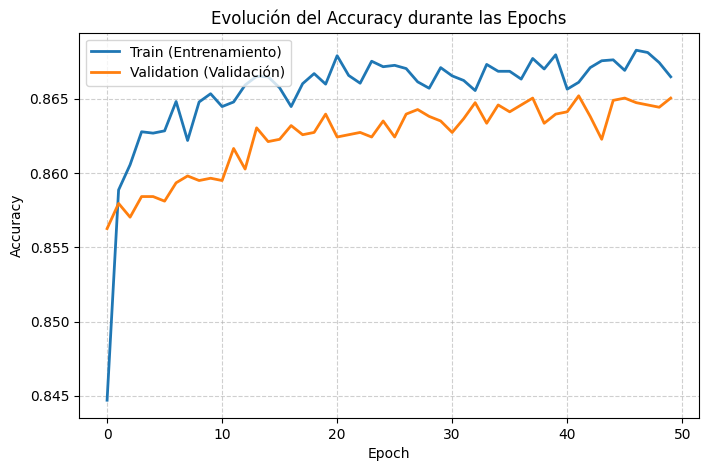

In [33]:
import matplotlib.pyplot as plt

# Definimos el tamaño del gráfico
plt.figure(figsize=(8, 5))

# Trazamos las dos curvas utilizando el objeto 'history'
plt.plot(history.history['accuracy'], label='Train (Entrenamiento)', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Validation (Validación)', linewidth=2)

# Configuramos títulos y etiquetas
plt.title('Evolución del Accuracy durante las Epochs')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(loc='upper left')

# Agregamos una grilla de fondo para facilitar la lectura
plt.grid(True, linestyle='--', alpha=0.6)

# Renderizamos el gráfico
plt.show()

In [30]:
# 1. Obtener la probabilidad de que devuelvan el préstamo (clase 1)
val_copy_rn = val.copy()

# Usamos X_val_transformado (los datos procesados) y aplanamos el resultado a 1D
probabilidades = model.predict(X_val_transformado)
val_copy_rn['Probabilidad_Pago'] = probabilidades.flatten()

# 2. Ordenar las solicitudes de mayor a menor probabilidad de pago
val_copy_rn = val_copy_rn.sort_values(by='Probabilidad_Pago', ascending=False)

# 3. Calcular el acumulado del presupuesto gastado
val_copy_rn['Monto_Acumulado'] = val_copy_rn['Monto_Solicitado'].cumsum()

# 4. Asignar la decisión final respetando el límite de 2.000.000 USD
LIMITE_PRESUPUESTO = 2000000

val_copy_rn['Aprobado_Negocio'] = (val_copy_rn['Monto_Acumulado'] <= LIMITE_PRESUPUESTO).astype(int)

# Ver cuántos préstamos pudimos financiar y cuántos rechazamos por falta de presupuesto
print(val_copy_rn['Aprobado_Negocio'].value_counts())

203/203 [==============================] - 0s 969us/step
Aprobado_Negocio
0    6357
1     127
Name: count, dtype: int64


In [31]:
# 1. Asegurar columnas de fecha en dataTest
dataTest['Fecha_Solicitud'] = pd.to_datetime(dataTest['Fecha_Solicitud'])
dataTest['Año_Solicitud']   = dataTest['Fecha_Solicitud'].dt.year
dataTest['Mes_Solicitud']   = dataTest['Fecha_Solicitud'].dt.month

# 2. Asegurar la unión con la información bancaria agregada
columnas_test_base = [
    'ID_Solicitud', 'ID_Usuario', 'Monto_Solicitado', 'Tasa_Interes', 
    'Ingreso_Mensual', 'Motivo_Prestamo', 'Fecha_Solicitud', 
    'Año_Solicitud', 'Mes_Solicitud'
]
dataTest_limpio = dataTest[columnas_test_base].copy()
dataTest = pd.merge(dataTest_limpio, dataBanco_agg, on='ID_Usuario', how='left').fillna(0)

# -------------------------------------------------------------------------
# NUEVO PASO: Transformar los datos crudos antes de dárselos a la Red Neuronal
# -------------------------------------------------------------------------
X_test_transformado = mapper.transform(dataTest)
X_test_transformado = imputer.transform(X_test_transformado)

# 3. Predecir probabilidades y aplicar la regla de los 2.000.000 USD
dataTest_resultados = dataTest.copy()

# Usamos model.predict en lugar de predict_proba y lo aplanamos a 1D
probabilidades_test = model.predict(X_test_transformado)
dataTest_resultados['Probabilidad_Pago'] = probabilidades_test.flatten()

# Ordenar por mejor perfil de pago y calcular monto acumulado
dataTest_resultados = dataTest_resultados.sort_values(by='Probabilidad_Pago', ascending=False)
dataTest_resultados['Monto_Acumulado'] = dataTest_resultados['Monto_Solicitado'].cumsum()

LIMITE_PRESUPUESTO = 2000000
dataTest_resultados['Decision_Aprobacion'] = (dataTest_resultados['Monto_Acumulado'] <= LIMITE_PRESUPUESTO).astype(int)

# Reordenar con el índice original de dataTest
dataTest_resultados = dataTest_resultados.sort_index()

# Ver resumen de aprobados/rechazados en Test
print(dataTest_resultados['Decision_Aprobacion'].value_counts())

# Generar el archivo de envío con las columnas clave
entrega_rn = dataTest_resultados[['ID_Solicitud', 'Decision_Aprobacion']]
entrega_rn.to_csv('Predicciones_Bianchini_Dutto_RN.csv', index=False)

96/96 [==============================] - 0s 2ms/step
Decision_Aprobacion
0    2282
1     779
Name: count, dtype: int64


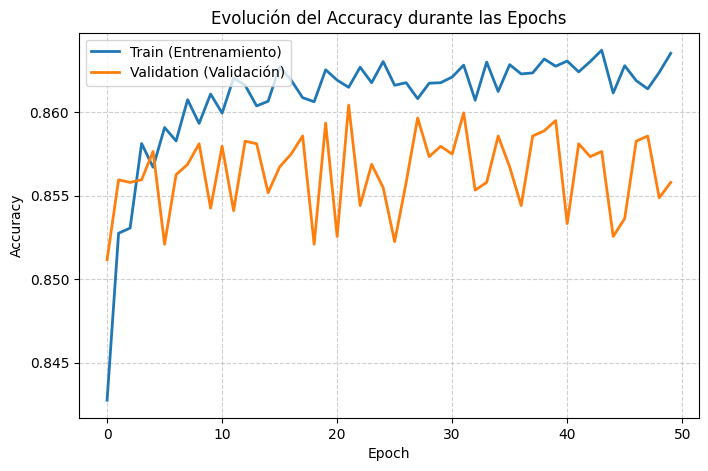

In [35]:
# Definimos el tamaño del gráfico
plt.figure(figsize=(8, 5))

# Trazamos las dos curvas utilizando el objeto 'history'
plt.plot(history_cnn.history['accuracy'], label='Train (Entrenamiento)', linewidth=2)
plt.plot(history_cnn.history['val_accuracy'], label='Validation (Validación)', linewidth=2)

# Configuramos títulos y etiquetas
plt.title('Evolución del Accuracy durante las Epochs')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(loc='upper left')

# Agregamos una grilla de fondo para facilitar la lectura
plt.grid(True, linestyle='--', alpha=0.6)

# Renderizamos el gráfico
plt.show()